# Gradient boosting on the validation years

One `HistGradientBoostingRegressor` per lead time, fitted on the training years (2000-2019) and scored on 2020-2022 against the simple forecasts.

Each model predicts how far the high h days ahead will be from that station's usual high on that date (the climatology from `scoring.py`). The usual high is then added back. This way the trees don't have to learn the seasons themselves.

In [1]:
import sys
sys.path.insert(0, "../data_scripts")  # relative to the working directory, which Jupyter sets to the notebook's folder

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from prepare_data import load_data
from scoring import LEADS, climatology, simple_forecasts, score

In [2]:
data = load_data()
usual = climatology(data)  # fitted on training years only
# Test years are never touched here.
keep = data.usable & data.period.isin(["train", "validation"])
print(f"{keep.sum():,} train and validation rows")

2,108,345 train and validation rows


## Features

Every feature uses only data through the forecast day t: the TMAX anomaly, TMIN and PRCP on days t to t-6.

There is no day-of-year feature. All 280 stations share each date's regional weather, so the day of year plus the anomalies picks out one day of one training year, and the trees memorize what came next. In a test at lead 4 it lowered training RMSE from 4.69 to 4.26 °C but raised validation RMSE from 5.21 to 5.39 °C. The seasons are already in the climatology the targets are measured from. Shifts are done per station on the full calendar table, so a shift of k rows is always k days. Missing values stay missing: HistGradientBoosting handles them itself.

In [3]:
anomaly = data.TMAX - usual(data.STATION, data.DATE)
features = {}
for k in range(7):
    features[f"anom_{k}"] = anomaly.groupby(data.STATION, sort=False).shift(k)[keep]
    features[f"tmin_{k}"] = data.TMIN.groupby(data.STATION, sort=False).shift(k)[keep]
    features[f"prcp_{k}"] = data.PRCP.groupby(data.STATION, sort=False).shift(k)[keep]
X = pd.DataFrame(features)

is_train = (data.period[keep] == "train").to_numpy()
train, rows = data[keep][is_train], data[keep][~is_train]
X_train, X_val = X[is_train], X[~is_train]
print(X.shape)

(2108345, 21)


In [4]:
predictions = {}
for h in LEADS:
    ahead = pd.Timedelta(days=h)
    # No early stopping: its random holdout shares dates with the training rows, so it can't see overfitting.
    model = HistGradientBoostingRegressor(max_iter=300, early_stopping=False, random_state=0)
    model.fit(X_train, train[f"y{h}"] - usual(train.STATION, train.DATE + ahead))
    predictions[f"y{h}"] = model.predict(X_val) + usual(rows.STATION, rows.DATE + ahead)
gb = pd.DataFrame(predictions, index=rows.index)

In [5]:
forecasts = simple_forecasts(data, rows)
scores = {name: score(rows, pred) for name, pred in forecasts.items()} | {"gradient boosting": score(rows, gb)}
mae = pd.DataFrame({name: s.MAE for name, s in scores.items()})
rmse = pd.DataFrame({name: s.RMSE for name, s in scores.items()})
mae.round(2)

,persistence,climatology,damped anomaly,gradient boosting
lead time,,,,
1,3.10,3.92,2.95,2.89
2,4.23,3.92,3.64,3.59
3,4.69,3.92,3.81,3.77
4,4.91,3.92,3.86,3.84
5,5.01,3.93,3.89,3.87
6,5.12,3.93,3.90,3.87
7,5.15,3.93,3.91,3.86


In [6]:
rmse.round(2)

,persistence,climatology,damped anomaly,gradient boosting
lead time,,,,
1,4.53,5.25,4.09,4.06
2,5.92,5.25,4.90,4.89
3,6.49,5.25,5.11,5.11
4,6.77,5.25,5.17,5.20
5,6.94,5.25,5.21,5.24
6,7.09,5.26,5.23,5.26
7,7.12,5.26,5.24,5.26


In [7]:
# Gain over the forecast to beat: positive means gradient boosting is better.
(mae["damped anomaly"] - mae["gradient boosting"]).round(3).rename("MAE gain (°C)")

lead time
1    0.059
2    0.054
3    0.041
4    0.026
5    0.022
6    0.035
7    0.043
Name: MAE gain (°C), dtype: float64

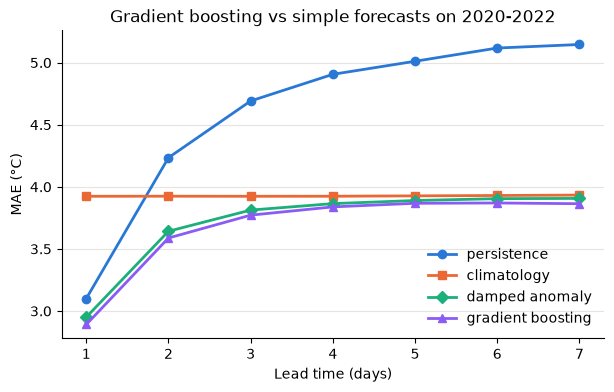

In [8]:
# Categorical slots 1-4 of the validated default palette; markers differ so identity is not color alone.
styles = {"persistence": ("#2a78d6", "o"), "climatology": ("#eb6834", "s"),
          "damped anomaly": ("#1baf7a", "D"), "gradient boosting": ("#8a5cf5", "^")}

fig, ax = plt.subplots(figsize=(7, 4))
for name, (color, marker) in styles.items():
    ax.plot(mae.index, mae[name], color=color, marker=marker, markersize=6, linewidth=2, label=name)
ax.set(xlabel="Lead time (days)", ylabel="MAE (°C)", title="Gradient boosting vs simple forecasts on 2020-2022", xticks=list(mae.index))
ax.grid(axis="y", color="#e5e4e0")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.show()

## Takeaways

* Gradient boosting has a lower MAE than damped anomaly, the best simple forecast, at every lead time. The gain is 0.06 °C at lead 1 and 0.02 to 0.04 °C from lead 4 on.
* RMSE is a different story: gradient boosting is level with damped anomaly at leads 1 to 3 and about 0.03 °C worse from lead 4 on. It does better on typical days but no better on the big misses.
* 2020-2022 ran warmer than the 2000-2019 climatology (about +0.37 °C at lead 4), and none of the features can tell the model that.
* This is a first result with default settings. Next: more past days, other weather elements, and nearby stations.